# FACTLENS FEVER Verifier — LoRA Fine-tuning (Subset + Proper Evaluation)

This notebook trains a **DeBERTa-v3-base three-class FEVER verifier using LoRA**. It is designed to run in Google Colab or Kaggle with a GPU.

**Important data assumptions**
- Input files are produced by `fever_data_prep.ipynb`: `train_classifier.jsonl` and `dev_classifier.jsonl`.
- Each SUPPORTS/REFUTES row must contain its complete gold evidence group.
- Each NEI row contains sampled corpus evidence. Randomly sampled evidence can occasionally be relevant; inspect errors and treat NEI label noise as a known limitation.
- The notebook samples a reproducible, stratified subset from the existing train and dev splits. It does not mix train and dev.
- `paper_dev_classifier.jsonl` / `paper_test_classifier.jsonl` are not used for training or model selection. Keep the paper test set untouched for final reporting.

**Evaluation:** accuracy, macro-F1, weighted-F1, per-class precision/recall/F1, confusion matrix, classification report, prediction CSV, and error analysis. The best checkpoint is selected by validation macro-F1.

## 1. Install dependencies

In [1]:
!pip -q install -U transformers peft accelerate datasets scikit-learn pandas matplotlib seaborn sentencepiece

## 2. Imports, reproducibility, and configuration

In [2]:
import os, json, random, time, gc
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, TrainingArguments, Trainer,
    EarlyStoppingCallback, set_seed
)
from peft import LoraConfig, TaskType, get_peft_model

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Update these paths for your runtime.
# Colab example: /content/drive/MyDrive/FACTLENS/fever-data/processed
# Kaggle example: /kaggle/input/your-dataset/processed
DATA_DIR = Path("/kaggle/input/datasets/lk1920/fever-data")
OUTPUT_DIR = Path("/kaggle/working/fever_deberta_lora_subset")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = DATA_DIR / "train_classifier.jsonl"
DEV_FILE = DATA_DIR / "dev_classifier.jsonl"

MODEL_NAME = "microsoft/deberta-v3-base"
MAX_LENGTH = 256

# Subset sizes: stratified independently within the official train/dev splits.
TRAIN_SUBSET_SIZE = 12000
DEV_SUBSET_SIZE = 2000

NUM_EPOCHS = 4
LEARNING_RATE = 2e-4
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 500
GRAD_ACCUM_STEPS = 1

# LoRA configuration
LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.10
LORA_TARGET_MODULES = ["query_proj", "value_proj"]

LABEL2ID = {"SUPPORTS": 0, "REFUTES": 1, "NEI": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Train file exists:", TRAIN_FILE.exists(), TRAIN_FILE)
print("Dev file exists:", DEV_FILE.exists(), DEV_FILE)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Train file exists: True /kaggle/input/datasets/lk1920/fever-data/train_classifier.jsonl
Dev file exists: True /kaggle/input/datasets/lk1920/fever-data/dev_classifier.jsonl


## 3. Load and validate the prepared FEVER data

In [3]:
def read_jsonl(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run fever_data_prep.ipynb first and make sure "
            "the processed JSONL files are in DATA_DIR."
        )
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if line.strip():
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError as e:
                    raise ValueError(f"Invalid JSON at {path}:{line_no}") from e
    return rows

train_raw = read_jsonl(TRAIN_FILE)
dev_raw = read_jsonl(DEV_FILE)

print("Raw train rows:", len(train_raw))
print("Raw dev rows:", len(dev_raw))
print("Train labels:", Counter(x.get("label") for x in train_raw))
print("Dev labels:", Counter(x.get("label") for x in dev_raw))

def validate_row(row):
    assert row.get("label") in LABEL2ID, f"Unexpected label: {row.get('label')}"
    assert isinstance(row.get("claim"), str) and row["claim"].strip(), "Missing claim"
    evidence = row.get("evidence")
    assert isinstance(evidence, list) and len(evidence) > 0, "Empty evidence"
    assert all(isinstance(e.get("text"), str) and e["text"].strip() for e in evidence), "Bad evidence text"
    if row["label"] in ("SUPPORTS", "REFUTES"):
        assert row.get("evidence_source") == "gold", "Positive label without gold evidence"
    if row["label"] == "NEI":
        assert row.get("evidence_source") == "sampled_corpus", "NEI row without sampled evidence"

for row in train_raw + dev_raw:
    validate_row(row)

print("Basic row validation passed.")

Raw train rows: 257115
Raw dev rows: 31391
Train labels: Counter({'SUPPORTS': 161249, 'REFUTES': 60227, 'NEI': 35639})
Dev labels: Counter({'SUPPORTS': 12498, 'REFUTES': 12227, 'NEI': 6666})
Basic row validation passed.


## 4. Inspect label/evidence examples before training

In [4]:
def show_examples(rows, n=2, seed=SEED):
    rng = random.Random(seed)
    for label in LABEL2ID:
        candidates = [r for r in rows if r["label"] == label]
        print("\\n" + "="*90 + "\\nLABEL:", label, "| available:", len(candidates))
        for row in rng.sample(candidates, min(n, len(candidates))):
            print("Claim:", row["claim"])
            print("Evidence source:", row.get("evidence_source"))
            for ev in row["evidence"][:4]:
                print(" -", ev["text"])
show_examples(train_raw, n=2)

\n==========================================================================================\nLABEL: SUPPORTS | available: 161249
Claim: Paleogene is a geologic period that spans 43 million years.
Evidence source: gold
 - The Paleogene -LRB- -LSB- pronˈpæliːədʒiːn -RSB- or -LSB- ˈpeɪliːədʒiːn -RSB- also spelled Palaeogene or Palæogene ; informally Lower Tertiary -RRB- is a geologic period and system that spans 43 million years from the end of the Cretaceous Period million years ago -LRB- Mya -RRB- to the beginning of the Neogene Period Mya .
Claim: Nikolaj Coster-Waldau is an actor.
Evidence source: gold
 - Nikolaj Coster-Waldau -LRB- -LSB- neɡ̊olaɪ̯ kʰʌsd̥ɐ ˈʋald̥ɑʊ̯ -RSB- ; born 27 July 1970 -RRB- is a Danish actor , producer and screenwriter .
\n==========================================================================================\nLABEL: REFUTES | available: 60227
Claim: Daft Punk is a single artist.
Evidence source: gold
 - Daft Punk are a French electronic music duo formed in

## 5. Build classifier inputs and sample subsets

We concatenate the claim and all sentences from one evidence group. This preserves the FEVER annotation unit: **one claim + one complete evidence group → one label**. We do not flatten individual evidence sentences into independent labels.

The subset is sampled separately within each official split and approximately preserves its label proportions.

In [5]:
def to_model_row(row):
    evidence_text = " ".join(
        ev["text"].strip() for ev in row["evidence"] if ev.get("text", "").strip()
    )
    text = (
        "Claim: " + row["claim"].strip() +
        "\\nEvidence: " + evidence_text
    )
    return {
        "id": str(row.get("id", "")),
        "text": text,
        "label": LABEL2ID[row["label"]],
        "label_name": row["label"],
        "evidence_source": row.get("evidence_source", "unknown"),
        "claim": row["claim"],
        "evidence_text": evidence_text,
    }

train_all = [to_model_row(r) for r in train_raw]
dev_all = [to_model_row(r) for r in dev_raw]

def stratified_subset(rows, max_size, seed):
    df = pd.DataFrame(rows)
    if max_size is None or max_size >= len(df):
        return df.sample(frac=1, random_state=seed).reset_index(drop=True).to_dict("records")
    # Allocate proportionally across labels, ensuring every available class is represented.
    counts = df["label"].value_counts()
    allocation = (counts / counts.sum() * max_size).round().astype(int)
    for label in counts.index:
        allocation[label] = max(1, allocation[label])
    while allocation.sum() > max_size:
        candidates = allocation[allocation > 1]
        if len(candidates) == 0: break
        allocation[candidates.idxmax()] -= 1
    while allocation.sum() < max_size:
        candidates = counts - allocation
        candidates = candidates[candidates > 0]
        if len(candidates) == 0: break
        allocation[candidates.idxmax()] += 1
    parts = []
    for label, n in allocation.items():
        group = df[df.label == label]
        parts.append(group.sample(n=min(int(n), len(group)), random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True).to_dict("records")

train_rows = stratified_subset(train_all, TRAIN_SUBSET_SIZE, SEED)
dev_rows = stratified_subset(dev_all, DEV_SUBSET_SIZE, SEED)

print("Subset sizes:", len(train_rows), len(dev_rows))
print("Train distribution:", Counter(x["label_name"] for x in train_rows))
print("Dev distribution:", Counter(x["label_name"] for x in dev_rows))

# Guard against accidental claim overlap across splits.
train_ids = {x["id"] for x in train_rows}
dev_ids = {x["id"] for x in dev_rows}
overlap = train_ids & dev_ids
print("Overlapping claim IDs:", len(overlap))
assert not overlap, "Train/dev claim ID overlap detected!" 

Subset sizes: 12000 2000
Train distribution: Counter({'SUPPORTS': 7526, 'REFUTES': 2811, 'NEI': 1663})
Dev distribution: Counter({'SUPPORTS': 796, 'REFUTES': 779, 'NEI': 425})
Overlapping claim IDs: 0


## 6. Tokenize the claim–evidence pairs

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

train_ds = Dataset.from_list(train_rows)
dev_ds = Dataset.from_list(dev_rows)

train_tokenized = train_ds.map(tokenize_batch, batched=True)
dev_tokenized = dev_ds.map(tokenize_batch, batched=True)

keep_columns = {"input_ids", "attention_mask", "label"}
if "token_type_ids" in train_tokenized.column_names:
    keep_columns.add("token_type_ids")
train_tokenized = train_tokenized.remove_columns(
    [c for c in train_tokenized.column_names if c not in keep_columns]
)
dev_tokenized = dev_tokenized.remove_columns(
    [c for c in dev_tokenized.column_names if c not in keep_columns]
)

print(train_tokenized)
print("Example token length:", len(train_tokenized[0]["input_ids"]))

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 12000
})
Example token length: 85


## 7. Load DeBERTa and attach LoRA adapters

In [10]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    dtype=torch.float32
)

# DeBERTa-v3 uses query_proj/key_proj/value_proj in its attention layers.
# Train the classifier head as well as the LoRA matrices.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGET_MODULES,
    modules_to_save=["classifier"],
    bias="none",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

# Fail early if target module names do not match this model version.
trainable = [n for n, p in model.named_parameters() if p.requires_grad]
assert any("lora_" in n for n in trainable), (
    "No LoRA parameters were attached. Inspect model.named_modules() and update target_modules."
)
assert any("classifier" in n for n in trainable), "Classifier head is not trainable."
print("Trainable parameter tensors:", len(trainable))

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

trainable params: 297,219 || all params: 184,721,670 || trainable%: 0.1609
Trainable parameter tensors: 50


## 8. Training configuration and metrics

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0),
    }

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),

    num_train_epochs=NUM_EPOCHS,

    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,

    gradient_accumulation_steps=GRAD_ACCUM_STEPS,

    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,

    warmup_steps=500,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=50,

    fp16=torch.cuda.is_available(),
    report_to="none",

    save_total_limit=2,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=dev_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(dev_tokenized))

Training examples: 12000
Validation examples: 2000


## 9. Train and save the best LoRA model

In [12]:
start_time = time.time()
train_result = trainer.train()
training_seconds = time.time() - start_time

BEST_MODEL_DIR = OUTPUT_DIR / "best_lora_model"
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# For PEFT models, save_pretrained saves adapter weights/config and modules_to_save.
trainer.model.save_pretrained(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)

print(f"Training time: {training_seconds/60:.2f} minutes")
print("Saved adapter to:", BEST_MODEL_DIR)
print("Best validation metrics:", trainer.evaluate())

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.497584,0.643542,0.915500,0.920455,0.914820
2,0.331567,0.556571,0.931000,0.934986,0.930638
3,0.269216,0.552752,0.940500,0.945348,0.940480
4,0.170662,0.540621,0.943500,0.947914,0.943507


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training time: 18.12 minutes
Saved adapter to: /kaggle/working/fever_deberta_lora_subset/best_lora_model


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1
0.170662,0.540621,4,0.943500,0.947914,0.943507


Best validation metrics: {'eval_loss': 0.5406206846237183, 'eval_accuracy': 0.9435, 'eval_macro_f1': 0.9479138524722589, 'eval_weighted_f1': 0.9435074207813229}


## 10. Full validation evaluation

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


VALIDATION METRICS
Accuracy: 0.9435
Macro-F1: 0.9479138524722589
Weighted-F1: 0.9435074207813229
\nClassification report:
              precision    recall  f1-score   support

    SUPPORTS     0.9262    0.9611    0.9433       796
     REFUTES     0.9395    0.9166    0.9279       779
         NEI     0.9855    0.9600    0.9726       425

    accuracy                         0.9435      2000
   macro avg     0.9504    0.9459    0.9479      2000
weighted avg     0.9440    0.9435    0.9435      2000



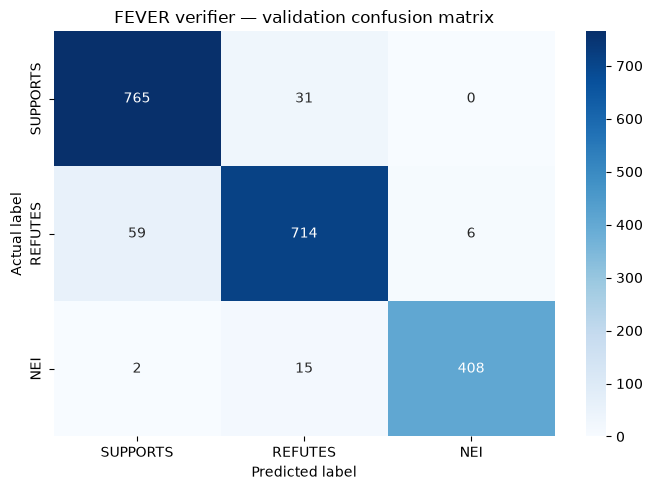

In [13]:
val_output = trainer.predict(dev_tokenized)
val_logits = val_output.predictions
val_true = val_output.label_ids
val_pred = np.argmax(val_logits, axis=1)

print("VALIDATION METRICS")
print("Accuracy:", accuracy_score(val_true, val_pred))
print("Macro-F1:", f1_score(val_true, val_pred, average="macro", zero_division=0))
print("Weighted-F1:", f1_score(val_true, val_pred, average="weighted", zero_division=0))
print("\\nClassification report:")
print(classification_report(
    val_true, val_pred,
    labels=[0,1,2],
    target_names=[ID2LABEL[i] for i in range(3)],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(val_true, val_pred, labels=[0,1,2])
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[ID2LABEL[i] for i in range(3)],
    yticklabels=[ID2LABEL[i] for i in range(3)]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("FEVER verifier — validation confusion matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_confusion_matrix.png", dpi=160)
plt.show()

## 11. Save per-example predictions and inspect errors

In [14]:
probs = torch.softmax(torch.tensor(val_logits), dim=1).numpy()
pred_df = pd.DataFrame({
    "id": [x["id"] for x in dev_rows],
    "claim": [x["claim"] for x in dev_rows],
    "evidence": [x["evidence_text"] for x in dev_rows],
    "evidence_source": [x["evidence_source"] for x in dev_rows],
    "gold_label": [ID2LABEL[int(x)] for x in val_true],
    "predicted_label": [ID2LABEL[int(x)] for x in val_pred],
    "confidence": probs.max(axis=1),
    "p_supports": probs[:, 0],
    "p_refutes": probs[:, 1],
    "p_nei": probs[:, 2],
})
pred_df["correct"] = pred_df["gold_label"] == pred_df["predicted_label"]

pred_path = OUTPUT_DIR / "validation_predictions.csv"
pred_df.to_csv(pred_path, index=False)
print("Saved:", pred_path)
print("Correct:", int(pred_df.correct.sum()), "/", len(pred_df))
print("Error count:", int((~pred_df.correct).sum()))

print("\\nMisclassified examples (first 20):")
display(pred_df.loc[~pred_df.correct, [
    "id", "gold_label", "predicted_label", "confidence",
    "claim", "evidence", "evidence_source"
]].head(20))

print("\\nErrors by gold label:")
display(
    pred_df.loc[~pred_df.correct].groupby("gold_label").size()
    .reindex(["SUPPORTS", "REFUTES", "NEI"], fill_value=0)
    .rename("error_count").to_frame()
)

Saved: /kaggle/working/fever_deberta_lora_subset/validation_predictions.csv
Correct: 1887 / 2000
Error count: 113
\nMisclassified examples (first 20):


,id,gold_label,predicted_label,confidence,claim,evidence,evidence_source
14,139661,SUPPORTS,REFUTES,0.986966,Colombiana was produced by Luc Besson in 2001.,Colombiana is a 2011 French action film co-wri...,gold
52,50537,REFUTES,SUPPORTS,0.840335,Mount Rushmore was built by Gutzon Borglum and...,Sculptor Gutzon Borglum created the sculpture ...,gold
83,103535,REFUTES,SUPPORTS,0.997381,Rick Ross released Hood Billionaire in 2010.,"In 2009 , Ross founded the record label Maybac...",gold
92,39499,SUPPORTS,REFUTES,0.965137,Season 2 of Fargo takes place in the 1970s.,"A prequel to the events in its first season , ...",gold
101,63557,REFUTES,SUPPORTS,0.977501,"Camden, New Jersey is the home of a school tha...",The city is the home of Rutgers University -- ...,gold
128,78264,REFUTES,SUPPORTS,0.998945,Vampires were living beings.,"In European folklore , vampires were undead be...",gold
164,66499,NEI,REFUTES,0.970609,The Invisible Man was a movie made in the era ...,"The film stars Sukumari , Jose Prakash , Kamal...",sampled_corpus
181,41780,SUPPORTS,REFUTES,0.971542,Britt Robertson was in the film series Girlboss.,"That same year , she headlined the Netflix com...",gold
194,116244,SUPPORTS,REFUTES,0.991635,Henry VIII (TV serial) stars an actor who was ...,It stars Ray Winstone in his first role in a c...,gold
207,76348,REFUTES,SUPPORTS,0.913420,"Sonny Bono died on February 16, 1935.",Salvatore Phillip `` Sonny '' Bono -LRB- -LSB-...,gold


\nErrors by gold label:


,error_count
gold_label,
SUPPORTS,31
REFUTES,65
NEI,17


## 12. Label/evidence audit

Use this audit to revisit the earlier concern that the actual label may not agree with the evidence. A model prediction differing from the gold label is not by itself proof that the annotation is wrong. Check whether the evidence actually supports/refutes the claim, whether it is complete, and whether a sampled NEI sentence accidentally contains relevant information.

In [15]:
# Print a small, reproducible sample of errors for manual annotation review.
errors = pred_df.loc[~pred_df.correct].copy()
for _, row in errors.sample(min(10, len(errors)), random_state=SEED).iterrows():
    print("\\n" + "="*100)
    print("ID:", row["id"])
    print("GOLD:", row["gold_label"], "| PRED:", row["predicted_label"],
          "| CONF:", round(float(row["confidence"]), 4))
    print("EVIDENCE SOURCE:", row["evidence_source"])
    print("CLAIM:", row["claim"])
    print("EVIDENCE:", row["evidence"])

# Also inspect random NEI training examples for possible accidental relevant evidence.
nei_train = [r for r in train_rows if r["label_name"] == "NEI"]
print("\\nRandom NEI examples — manually verify these are genuinely insufficient:")
for row in random.Random(SEED).sample(nei_train, min(8, len(nei_train))):
    print("\\nClaim:", row["claim"])
    print("Evidence:", row["evidence_text"])

\n====================================================================================================
ID: 39185
GOLD: NEI | PRED: REFUTES | CONF: 0.5495
EVIDENCE SOURCE: sampled_corpus
CLAIM: The Love Club EP isn't long enough to qualify as an album.
EVIDENCE: The High Court and Court of Appeal have yet to render any judgment on the issue .
\n====================================================================================================
ID: 63557
GOLD: REFUTES | PRED: SUPPORTS | CONF: 0.9775
EVIDENCE SOURCE: gold
CLAIM: Camden, New Jersey is the home of a school that was founded as the South Jersey Law School in 1920.
EVIDENCE: The city is the home of Rutgers University -- Camden , which was founded as the South Jersey Law School in 1926 , and Cooper Medical School of Rowan University , which opened in 2012 .
\n====================================================================================================
ID: 68337
GOLD: REFUTES | PRED: SUPPORTS | CONF: 0.9494
EVIDENCE SOURC

## 13. Training curves and run summary

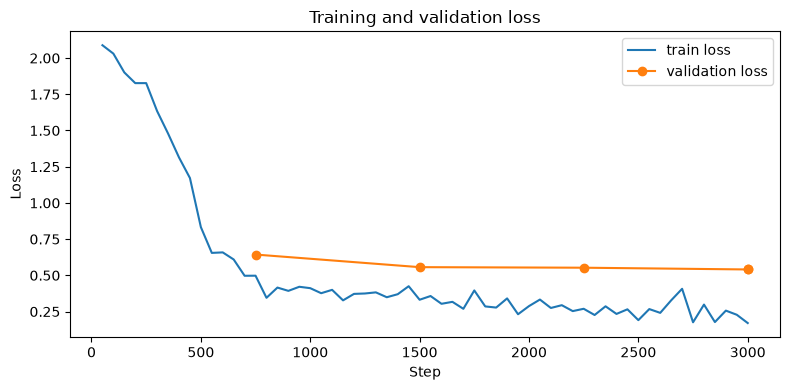

{'base_model': 'microsoft/deberta-v3-base',
 'method': 'LoRA sequence classification',
 'train_subset_size': 12000,
 'validation_subset_size': 2000,
 'train_label_distribution': {'SUPPORTS': 7526, 'REFUTES': 2811, 'NEI': 1663},
 'validation_label_distribution': {'NEI': 425,
  'SUPPORTS': 796,
  'REFUTES': 779},
 'max_length': 256,
 'lora_r': 8,
 'lora_alpha': 16,
 'lora_dropout': 0.1,
 'lora_target_modules': ['query_proj', 'value_proj'],
 'training_seconds': 1087.3304579257965,
 'validation_accuracy': 0.9435,
 'validation_macro_f1': 0.9479138524722589,
 'validation_weighted_f1': 0.9435074207813229,
 'best_checkpoint': '/kaggle/working/fever_deberta_lora_subset/checkpoints/checkpoint-3000'}

In [16]:
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUTPUT_DIR / "training_log_history.csv", index=False)

if "loss" in history:
    train_loss = history.dropna(subset=["loss"])
    plt.figure(figsize=(8,4))
    plt.plot(train_loss["step"], train_loss["loss"], label="train loss")
    if "eval_loss" in history:
        eval_loss = history.dropna(subset=["eval_loss"])
        if len(eval_loss):
            plt.plot(eval_loss["step"], eval_loss["eval_loss"], marker="o", label="validation loss")
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=160)
    plt.show()

summary = {
    "base_model": MODEL_NAME,
    "method": "LoRA sequence classification",
    "train_subset_size": len(train_rows),
    "validation_subset_size": len(dev_rows),
    "train_label_distribution": dict(Counter(x["label_name"] for x in train_rows)),
    "validation_label_distribution": dict(Counter(x["label_name"] for x in dev_rows)),
    "max_length": MAX_LENGTH,
    "lora_r": LORA_R,
    "lora_alpha": LORA_ALPHA,
    "lora_dropout": LORA_DROPOUT,
    "lora_target_modules": LORA_TARGET_MODULES,
    "training_seconds": training_seconds,
    "validation_accuracy": float(accuracy_score(val_true, val_pred)),
    "validation_macro_f1": float(f1_score(val_true, val_pred, average="macro", zero_division=0)),
    "validation_weighted_f1": float(f1_score(val_true, val_pred, average="weighted", zero_division=0)),
    "best_checkpoint": trainer.state.best_model_checkpoint,
}
with open(OUTPUT_DIR / "run_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
summary

## 14. Optional: evaluate a separate untouched paper-dev or paper-test set

Only run this after choosing the model using the validation subset. This cell uses the prepared JSONL file as-is and does not train on it. Change `FINAL_EVAL_FILE` to `paper_dev_classifier.jsonl` or `paper_test_classifier.jsonl`. Do not use paper-test results to tune hyperparameters.

In [18]:
# Set to None to skip. Keep paper_test untouched until final reporting.
FINAL_EVAL_FILE = DATA_DIR / "paper_test_classifier.jsonl"

if FINAL_EVAL_FILE is not None:
    final_raw = read_jsonl(Path(FINAL_EVAL_FILE))
    final_rows = [to_model_row(r) for r in final_raw]
    final_ds = Dataset.from_list(final_rows).map(tokenize_batch, batched=True)
    final_ds = final_ds.remove_columns(
        [c for c in final_ds.column_names if c not in keep_columns]
    )
    final_result = trainer.predict(final_ds)
    final_true = final_result.label_ids
    final_pred = np.argmax(final_result.predictions, axis=1)
    print(classification_report(
        final_true, final_pred,
        labels=[0,1,2],
        target_names=[ID2LABEL[i] for i in range(3)],
        digits=4, zero_division=0
    ))
    print("Accuracy:", accuracy_score(final_true, final_pred))
    print("Macro-F1:", f1_score(final_true, final_pred, average="macro", zero_division=0))

Map:   0%|          | 0/15616 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

    SUPPORTS     0.9091    0.9615    0.9346      6291
     REFUTES     0.9414    0.8949    0.9175      5992
         NEI     0.9822    0.9625    0.9723      3333

    accuracy                         0.9362     15616
   macro avg     0.9442    0.9396    0.9415     15616
weighted avg     0.9371    0.9362    0.9361     15616

Accuracy: 0.9361552254098361
Macro-F1: 0.9414533674533843


## Notes / limitations

1. **This is LoRA, not QLoRA.** The frozen base model is loaded in its normal precision. LoRA reduces trainable parameters and optimizer state; it does not quantize the backbone.
2. CPU inference is still possible by loading the base model plus adapter on CPU, but CPU speed depends on model size, sequence length, batch size, and hardware. For faster deployment, merge the adapter and evaluate INT8 dynamic quantization or ONNX Runtime separately.
3. The prepared dataset's NEI evidence is randomly sampled. A sampled sentence can accidentally be relevant, creating label noise. Manual audit or hard-negative filtering can improve this.
4. The notebook treats each alternative gold evidence group as a separate positive training example. Claims with multiple gold groups therefore appear multiple times, which is intentional for group-level supervision.
5. Subset metrics are for rapid iteration, not final paper results. Once the pipeline is stable, train with the full official training split and evaluate once on the untouched test split.